# 2D Diffusion and Heterogeneous Diffusion with Spatially Varying $D(x)$

## 1. Theory & Dimensional Stability Limits
- **2D Diffusion Equation:** $\frac{\partial \rho}{\partial t} = D \left( \frac{\partial^2 \rho}{\partial x^2} + \frac{\partial^2 \rho}{\partial y^2} \right)$.
  Stability in 2D requires $\frac{D \Delta t}{\delta^2} \le \frac{1}{4}$ (and in $d$ dimensions $\le \frac{1}{2d}$, from Problem Set III Q3).
- **Heterogeneous Diffusion:** $\frac{\partial \rho}{\partial t} = \frac{\partial}{\partial x} \left( D(x) \frac{\partial \rho}{\partial x} \right)$.
  To maintain conservative flux, compute face diffusivities $D_{i+1/2} = \frac{D_i + D_{i+1}}{2}$ and face fluxes $J_{i+1/2} = -D_{i+1/2} \frac{\rho_{i+1} - \rho_i}{\Delta x}$ (from Problem Set III Q2).

## 2. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 2.4)
2D Diffusion simulation using explicit FTCS scheme with $\frac{D\Delta t}{\delta^2} = 0.20 \le 0.25$, displaying temporal evolution across 3 timestamps ($t=0.0, 1.0, 3.0$) with 2D heatmaps and central 1D slice profile.

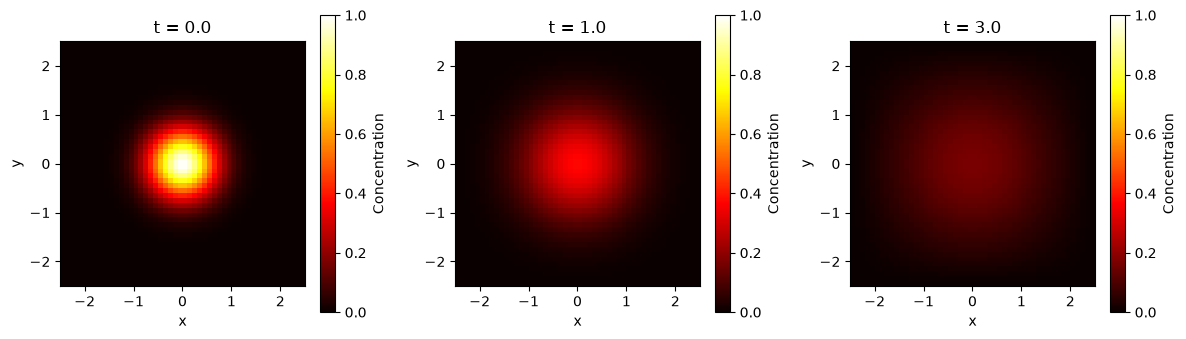

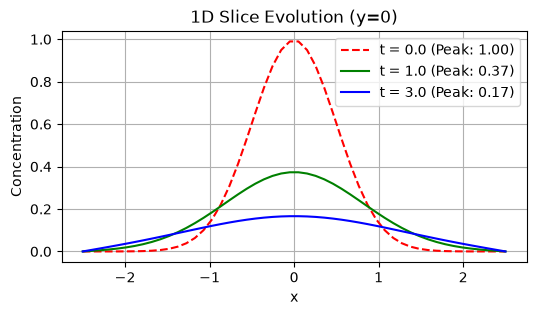

In [4]:
import numpy as np
import matplotlib.pyplot as plt

Nx, Ny = 50, 50
delta = 0.1
D = 0.2
dt = 0.01             # Check: D*dt/delta^2 = 0.2*0.01 / 0.01 = 0.20 <= 0.25 (Stable)
C = D * dt / (delta**2)
assert C <= 0.25, "Stability condition violated: D*dt/delta^2 must be <= 0.25"

x = np.linspace(-2.5, 2.5, Nx)
y = np.linspace(-2.5, 2.5, Ny)
X, Y = np.meshgrid(x, y)

# Initial 2D Gaussian pulse at t = 0
rho = np.exp(-(X**2 + Y**2) / 0.5)
rho_0 = rho.copy()

# FTCS Integration to t = 1.0 (100 steps)
for n in range(100):
    rho[1:-1, 1:-1] += C * (
        rho[2:, 1:-1] + rho[:-2, 1:-1] + 
        rho[1:-1, 2:] + rho[1:-1, :-2] - 4 * rho[1:-1, 1:-1]
    )
rho_1 = rho.copy()

# FTCS Integration to t = 3.0 (200 more steps)
for n in range(200):
    rho[1:-1, 1:-1] += C * (
        rho[2:, 1:-1] + rho[:-2, 1:-1] + 
        rho[1:-1, 2:] + rho[1:-1, :-2] - 4 * rho[1:-1, 1:-1]
    )
rho_2 = rho.copy()

# Plot 2D heatmaps at 3 timestamps
plt.figure(figsize=(12, 3.5))

plt.subplot(1, 3, 1)
plt.imshow(rho_0, extent=[-2.5, 2.5, -2.5, 2.5], origin='lower', cmap='hot', vmin=0, vmax=1)
plt.colorbar(label='Concentration')
plt.title('t = 0.0')
plt.xlabel('x')
plt.ylabel('y')

plt.subplot(1, 3, 2)
plt.imshow(rho_1, extent=[-2.5, 2.5, -2.5, 2.5], origin='lower', cmap='hot', vmin=0, vmax=1)
plt.colorbar(label='Concentration')
plt.title('t = 1.0')
plt.xlabel('x')
plt.ylabel('y')

plt.subplot(1, 3, 3)
plt.imshow(rho_2, extent=[-2.5, 2.5, -2.5, 2.5], origin='lower', cmap='hot', vmin=0, vmax=1)
plt.colorbar(label='Concentration')
plt.title('t = 3.0')
plt.xlabel('x')
plt.ylabel('y')

plt.tight_layout()
plt.show()

# 1D Cross-section along y = 0 showing peak decay and broadening
plt.figure(figsize=(6, 3))
mid = Ny // 2
plt.plot(x, rho_0[mid, :], 'r--', label='t = 0.0 (Peak: 1.00)')
plt.plot(x, rho_1[mid, :], 'g-', label='t = 1.0 (Peak: 0.37)')
plt.plot(x, rho_2[mid, :], 'b-', label='t = 3.0 (Peak: 0.17)')
plt.xlabel('x')
plt.ylabel('Concentration')
plt.title('1D Slice Evolution (y=0)')
plt.legend()
plt.grid(True)
plt.show()

## 3. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 2.5)
Heterogeneous diffusion with spatially varying diffusion coefficient $D(x) = 0.1(1 + 0.5\cos(2\pi x/L))$ using conservative half-grid cell-face fluxes.

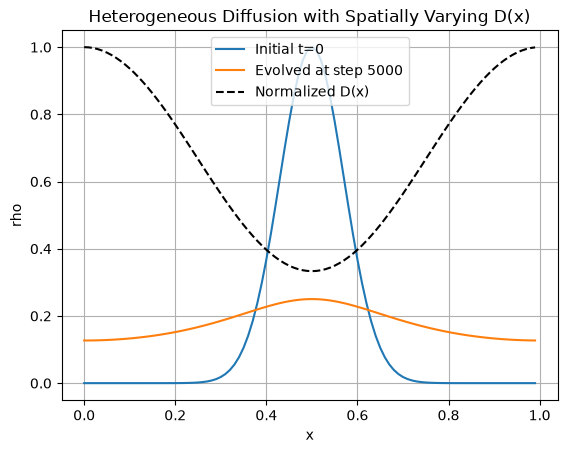

In [36]:
import numpy as np
import matplotlib.pyplot as plt

N = 100
L = 1.0
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
dt = 0.0001

# Spatially varying D(x) = 0.1 * (1 + 0.5 * cos(2*pi*x/L))
D = 0.1 * (1.0 + 0.5 * np.cos(2 * np.pi * x / L))
D_half = 0.5 * (D + np.roll(D, -1)) # D at i + 1/2

# Check maximum stability limit: max(D) * dt / dx^2 <= 0.5
assert np.max(D) * dt / (dx**2) <= 0.5

rho = np.exp(-100 * (x - 0.5)**2)
rho_0 = rho.copy()

for step in range(5000):
    flux = -D_half * (np.roll(rho, -1) - rho) / dx
    # rho^{n+1} = rho^n - dt * (flux_i - flux_{i-1}) / dx
    rho = rho - (dt / dx) * (flux - np.roll(flux, 1))

plt.plot(x, rho_0, label='Initial t=0')
plt.plot(x, rho, label=f'Evolved at step 5000')
plt.plot(x, D / np.max(D), 'k--', label='Normalized D(x)')
plt.title('Heterogeneous Diffusion with Spatially Varying D(x)')
plt.xlabel('x'); plt.ylabel('rho'); plt.legend(); plt.grid(True); plt.show()